In [ ]:
---
execute:
  eval: false
  echo: true
  warning: false
format:
  html:
    code-fold: false
---

Importing the packages.

In [13]:
#| echo: true
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

Creating a synthetic dataset.

In [14]:
#| echo: true
data, _ = make_moons(n_samples=1000, noise=0.05)
data = (data - data.mean(axis=0)) / data.std(axis=0)
dataset = torch.tensor(data, dtype=torch.float32)

Defining the noise scales for SMLD.

In [15]:
#| echo: true
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

L = 10
sigma_1 = 2.0
sigma_L = 0.01

sigmas = torch.tensor(
    np.exp(np.linspace(np.log(sigma_1), np.log(sigma_L), L)),
    dtype=torch.float32,
    device=device
)

Creating a small neural network.

In [16]:
#| echo: true
class SMLD(nn.Module):
    def __init__(self, num_scales=10, hidden_dim=128):
        super().__init__()
        self.scale_embed = nn.Embedding(num_scales, hidden_dim)

        self.net = nn.Sequential(
            nn.Linear(2 + hidden_dim, hidden_dim),
            nn.Softplus(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Softplus(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Softplus(),
            nn.Linear(hidden_dim, 2)
        )

    def forward(self, x, scale_idx):
        embed = self.scale_embed(scale_idx)
        h = torch.cat([x, embed], dim=-1)
        return self.net(h)

model = SMLD(num_scales=L, hidden_dim=128).to(device)

Training the model.

In [19]:
#| echo: true
optimizer = optim.Adam(model.parameters(), lr=1e-3)

batch_size = 128
epochs = 1000
data_loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)

model.train()
for epoch in range(1, epochs + 1):
    total_loss = 0.0
    for x0 in data_loader:
        x0 = x0.to(device)
        idx = torch.randint(0, L, (x0.size(0),), device=device)
        used_sigmas = sigmas[idx].unsqueeze(-1)

        z = torch.randn_like(x0)
        xt = x0 + used_sigmas * z

        score = model(xt, idx)

        loss = 0.5 * torch.sum((score * used_sigmas + z) ** 2, dim=-1).mean()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    if epoch % 100 == 0 or epoch == 1:
        print(f"Epoch [{epoch:04d}/{epochs}] | Loss: {total_loss / len(data_loader):.4f}")

Epoch [0001/1000] | Loss: 0.9757
Epoch [0100/1000] | Loss: 0.8504
Epoch [0200/1000] | Loss: 0.8290
Epoch [0300/1000] | Loss: 0.8124
Epoch [0400/1000] | Loss: 0.7555
Epoch [0500/1000] | Loss: 0.8176
Epoch [0600/1000] | Loss: 0.7526
Epoch [0700/1000] | Loss: 0.8006
Epoch [0800/1000] | Loss: 0.7274
Epoch [0900/1000] | Loss: 0.7304
Epoch [1000/1000] | Loss: 0.7371


Sampling using Annealed Langevin Dynamics.

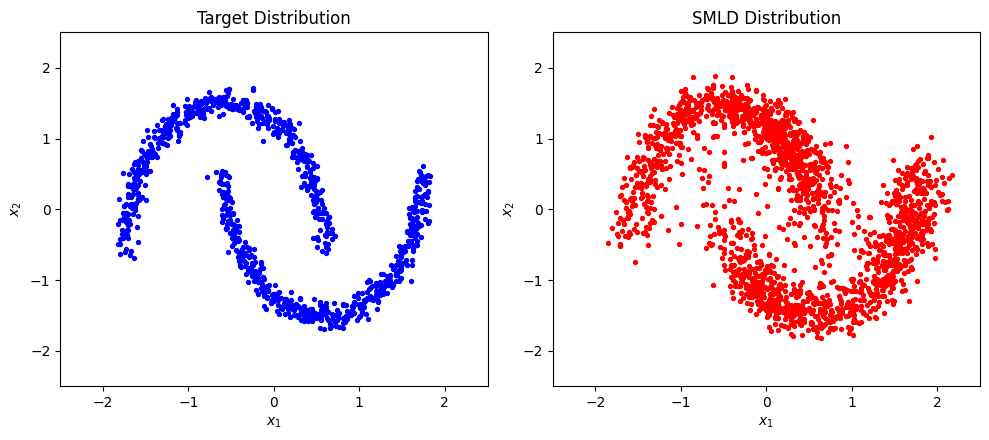

In [20]:
#| echo: true
@torch.no_grad()
def annealed_langevin_dynamics(model, sigmas, n_samples, n_steps_per_scale, eps=2e-5):
    model.eval()

    x = torch.randn(n_samples, 2, device=device) * sigmas[0]

    for i, sigma in enumerate(sigmas):
        alpha = eps * (sigma / sigmas[-1]) ** 2
        idx_tensor = torch.full((n_samples,), i, dtype=torch.long, device=device)

        for _ in range(n_steps_per_scale):
            z = torch.randn_like(x)
            score = model(x, idx_tensor)
            x = x + 0.5 * alpha * score + torch.sqrt(alpha) * z

    return x.cpu().numpy()

generated_samples = annealed_langevin_dynamics(
    model, sigmas, n_samples=2000, n_steps_per_scale=100, eps=2e-5
)
real_data = dataset.cpu().numpy()

plt.figure(figsize=(10, 4.5))

plt.subplot(1, 2, 1)
plt.scatter(real_data[:, 0], real_data[:, 1], s=8, color="blue")
plt.title("Target Distribution")
plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$")
plt.xlim(-2.5, 2.5)
plt.ylim(-2.5, 2.5)

plt.subplot(1, 2, 2)
plt.scatter(generated_samples[:, 0], generated_samples[:, 1], s=8, color="red")
plt.title("SMLD Distribution")
plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$")
plt.xlim(-2.5, 2.5)
plt.ylim(-2.5, 2.5)

plt.tight_layout()
plt.show()